# Loading data

In [ ]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from random import randint
import torch
from torch import nn

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "src/model/rnn_loader.py").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from model.rnn_loader import load_rnn_model, checkpoint_parameters
from model.training.train import read_csv, prepare_sequences
from model.export_rnn import export_onnx
DATA_DIR = PROJECT_ROOT / "data/generated_data"
MAX_TRAJECTORIES = None  # Set an integer for a quick data/evaluation check.

from policy.lib.droneEnvRotation import PARAMS
MODEL_PATH = PROJECT_ROOT / "src/model/checkpoints/rnn_model_thrust_speeds.pt"
ONNX_PATH = MODEL_PATH.with_suffix(".onnx")
model = load_rnn_model(MODEL_PATH)
params = checkpoint_parameters(model, PARAMS, "z_psi")
# These raw datasets can be replaced with the cleaned db_inputs2/db_outputs2
# using input_format="controls", output_format="selected" below.
data_in, data_out = prepare_sequences(
    read_csv(DATA_DIR / "db_regime6_helico_input.csv", MAX_TRAJECTORIES),
    read_csv(DATA_DIR / "db_regime6_helico_output.csv", MAX_TRAJECTORIES),
    "z_psi", "motors", "plant",
)
data_in_torch = torch.from_numpy(data_in)
data_out_torch = torch.from_numpy(data_out)
nb_data = len(data_in)


Normalizing accordingly to training data

In [14]:
train_size = int(0.9 * nb_data)
val_size = 0
test_size = nb_data - train_size
scale = np.where(params.sigma_u == 0, 1, params.sigma_u)
input_data = torch.from_numpy((data_in - params.mean_u) / scale)
output_mean = np.array([params.mean_az, params.mean_wz_dot], dtype=np.float32)
output_scale = np.array([params.sigma_az, params.sigma_wz_dot], dtype=np.float32)
output_data = torch.from_numpy((data_out - output_mean) / output_scale)


# Testing via Torch model

In [15]:
hidden_layer_size = model.rnn.hidden_size
print(model)


<All keys matched successfully>

# Computing max errors of the model against test data

In [16]:
idx_measure = 0
with torch.inference_mode():
    prediction, _ = model(input_data[train_size + val_size:])
distances = np.abs(prediction.numpy() - output_data[train_size + val_size:].numpy())
mean_distances = distances[..., idx_measure].mean(axis=1)
max_distances = distances[..., idx_measure].max(axis=1)
distances.shape, mean_distances.shape, max_distances.shape


((500, 161, 2), (500,), (500,))

In [6]:
print(np.sum(np.isnan(distances)))

0


Text(0.5, 0, 'Time step')

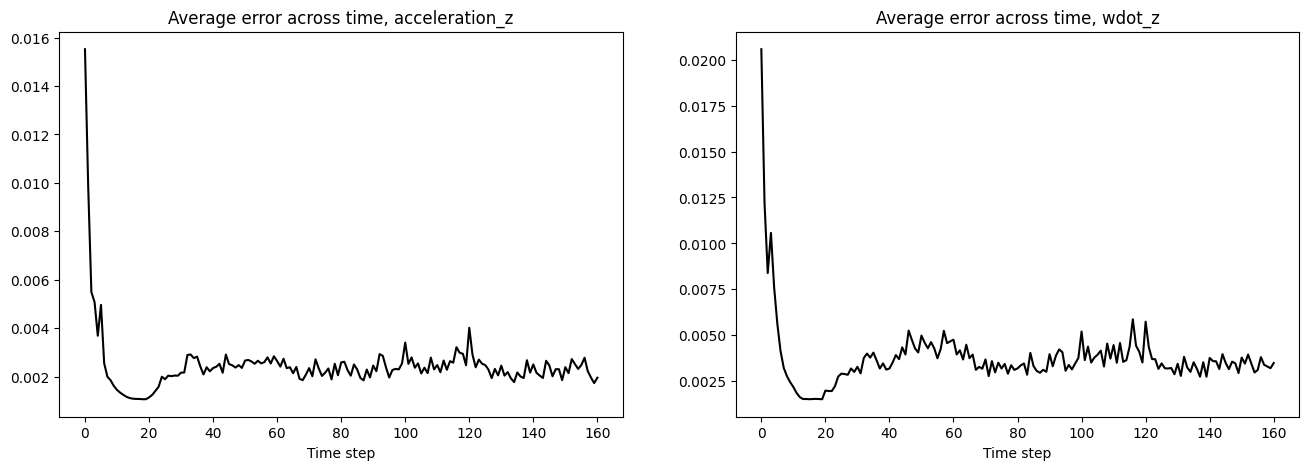

In [17]:
average_on_test = np.mean(distances, axis=0)
fig, axes = plt.subplots(1, 2)
fig.set_figheight(5)
fig.set_figwidth(16)

axes[0].plot(average_on_test[:, 0], c="black")
axes[0].set_title("Average error across time, acceleration_z")
axes[0].set_xlabel("Time step")
axes[1].plot(average_on_test[:, 1], c="black")
axes[1].set_title("Average error across time, wdot_z")
axes[1].set_xlabel("Time step")

(array([11., 14., 24., 24., 43., 38., 38., 26., 31., 34., 26., 23., 12.,
        24., 17., 17.,  6.,  6.,  6.,  6.,  6.,  4.,  8.,  2.,  1.,  2.,
         2.,  3.,  3.,  2.,  3.,  5.,  3.,  3.,  2.,  1.,  1.,  1.,  4.,
         0.,  0.,  1.,  1.,  0.,  0.,  1.,  0.,  1.,  0.,  2.,  0.,  1.,
         1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  1.,  0.,
         0.,  0.,  1.,  0.,  0.,  0.,  1.,  1.,  1.,  0.,  0.,  1.,  1.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.01529318, 0.01815948, 0.02102578, 0.02389207, 0.02675837,
        0.02962467, 0.03249096, 0.03535726, 0.03822356, 0.04108985,
        0.04395615, 0.04682245, 0.04968874, 0.05255504, 0.05542134,
        0.05828763, 0.06115393, 0.06402023, 0.06688652, 0.06975282,
        0.07261912, 0.07548541, 0.07835171, 0.081218  , 0.0840843 ,
        0.0869506 , 0.0898169 , 0.0926832 , 0.09554949, 0.09841578,
        0.10128208, 0.1041

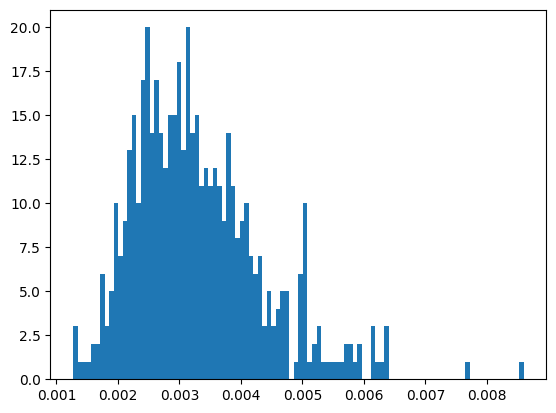

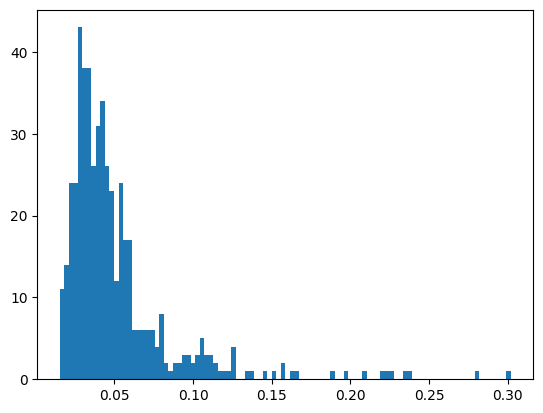

In [8]:
plt.figure()
plt.hist(mean_distances, bins=100)
plt.figure()
plt.hist(max_distances, bins=100)

Comparing for a given sample

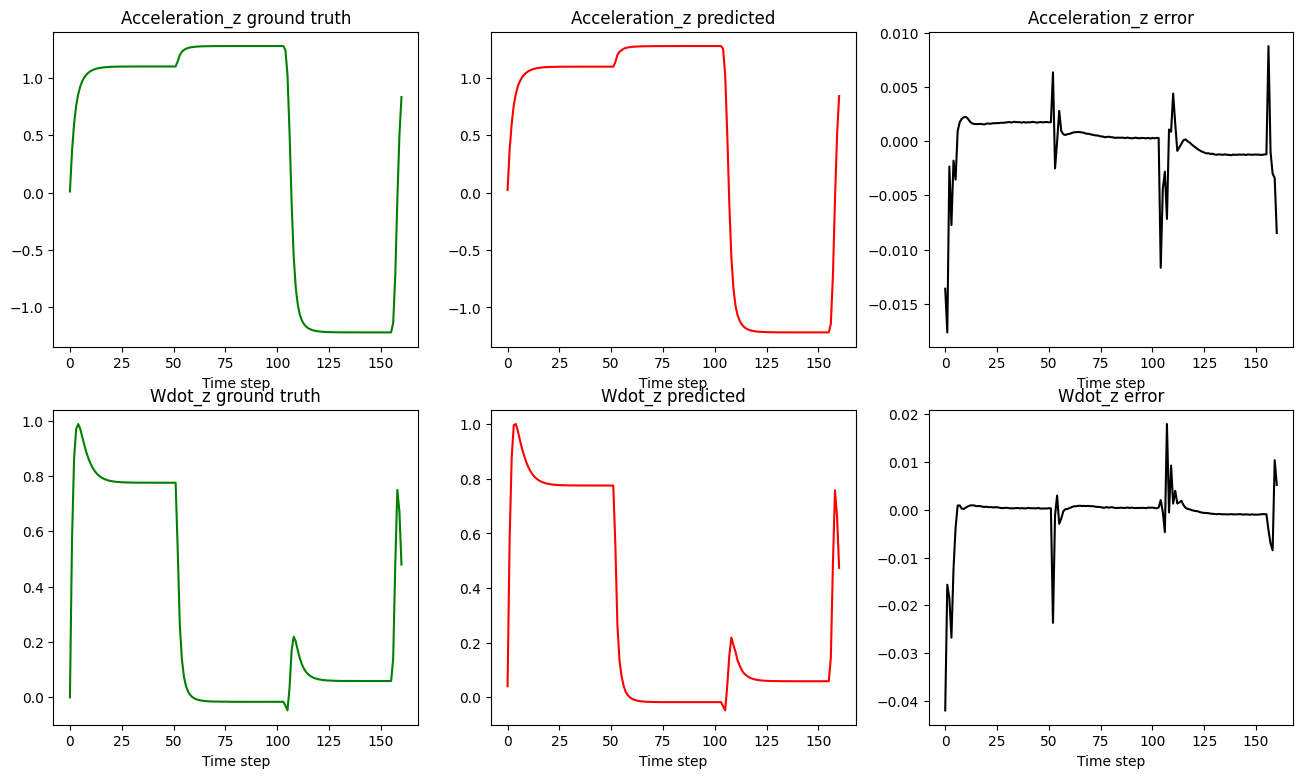

In [29]:
train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)
idx = test_rand_idx

full_sequence = input_data[idx].unsqueeze(0)
h = torch.zeros((1, 1, hidden_layer_size))

outputs_list = []
for t in range(full_sequence.size(1)):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = model(x_step, h)
    outputs_list.append(out)
    
outputs_cat = torch.cat(outputs_list, axis=1)

fig, axes = plt.subplots(2, 3)
fig.set_figheight(9)
fig.set_figwidth(16)
plt.plot()

titles = [["Acceleration_z ground truth", "Acceleration_z predicted", "Acceleration_z error"], ["Wdot_z ground truth", "Wdot_z predicted", "Wdot_z error"]]
for i in range(2):
    for j in range(3):
        axes[i, j].set_title(titles[i][j])
        axes[i, j].set_xlabel("Time step")
    
    axes[i, 0].plot(output_data[idx][:, i].detach().numpy(), c="green")
    axes[i, 1].plot(outputs_cat[0][:, i].detach().numpy(), c="red")
    axes[i, 2].plot(output_data[idx][:, i].detach().numpy() - outputs_cat[0][:, i].detach().numpy(), c="black")

# ONNX version (not working yet)

In [ ]:
import onnx
import onnxruntime
if not ONNX_PATH.is_file():
    export_onnx(model, ONNX_PATH)
onnx.checker.check_model(onnx.load(str(ONNX_PATH)))


In [ ]:
input_data.size()

torch.Size([1960, 161, 4])

In [ ]:
ort_session = onnxruntime.InferenceSession(
    str(ONNX_PATH), providers=["CPUExecutionProvider"]
)

input_names = [inp.name for inp in ort_session.get_inputs()]
x_name = input_names[0]
h_name = input_names[1]

train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)
idx = test_rand_idx

full_sequence = input_data[idx].reshape(1, -1, 4).numpy()

hidden_size = model.rnn.hidden_size
h = np.zeros((1, 1, hidden_size), dtype=np.float32)

onnxruntime_outputs_list = []

for t in range(full_sequence.shape[1]):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = ort_session.run(
        None, 
        {x_name: x_step, h_name: h}
    )
    onnxruntime_outputs_list.append(out)

onnxruntime_outputs = np.concatenate(onnxruntime_outputs_list, axis=1)

plt.plot(input_data[idx].numpy(), c="blue", alpha=0.3)
plt.plot(output_data[idx].numpy(), c="green", alpha=0.5)
plt.plot(onnxruntime_outputs[0], c="red", alpha=0.7)

# plt.plot(output_data[idx] - onnxruntime_outputs[:, :][0][:, 0], c="blue")
plt.show()

InvalidArgument: [ONNXRuntimeError] : 2 : INVALID_ARGUMENT : Got invalid dimensions for input: x for the following indices
 index: 1 Got: 1 Expected: 5
 Please fix either the inputs/outputs or the model.